In [4]:
# try:
#   # This command only in Colab.
#   %tensorflow_version 2.x
# except Exception:
#   pass
import tensorflow as tf

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Conv2D, Flatten, Dropout, MaxPooling2D
from tensorflow.keras.preprocessing.image import ImageDataGenerator

import os
import numpy as np
import matplotlib.pyplot as plt

In [5]:
# Get project files
!wget https://cdn.freecodecamp.org/project-data/cats-and-dogs/cats_and_dogs.zip

!unzip cats_and_dogs.zip

PATH = 'cats_and_dogs'

train_dir = os.path.join(PATH, 'train')
validation_dir = os.path.join(PATH, 'validation')
test_dir = os.path.join(PATH, 'test')

# Get number of files in each directory. The train and validation directories
# each have the subdirecories "dogs" and "cats".
total_train = sum([len(files) for r, d, files in os.walk(train_dir)])
total_val = sum([len(files) for r, d, files in os.walk(validation_dir)])
total_test = len(os.listdir(test_dir))

# Variables for pre-processing and training.
batch_size = 128
epochs = 15
IMG_HEIGHT = 150
IMG_WIDTH = 150

^C


In [47]:
# 3

train_image_generator = ImageDataGenerator(rescale=1./255)

validation_image_generator = ImageDataGenerator(rescale=1./255)

test_image_generator = ImageDataGenerator(rescale=1./255)

train_data_gen = train_image_generator.flow_from_directory(directory=train_dir, 
                                                            target_size=(IMG_HEIGHT,IMG_WIDTH),
                                                            batch_size=batch_size)
                                                                         
val_data_gen = validation_image_generator.flow_from_directory(directory=validation_dir, 
                                                            target_size=(IMG_HEIGHT,IMG_WIDTH),
                                                            batch_size=batch_size,
                                                            class_mode="sparse")

test_data_gen = test_image_generator.flow_from_directory(directory=PATH, 
                                                            target_size=(IMG_HEIGHT,IMG_WIDTH),
                                                            classes=['test'], 
                                                            batch_size=batch_size,
                                                            class_mode= None,
                                                            shuffle=False)



Found 2000 images belonging to 2 classes.
Found 1000 images belonging to 2 classes.
Found 50 images belonging to 1 classes.


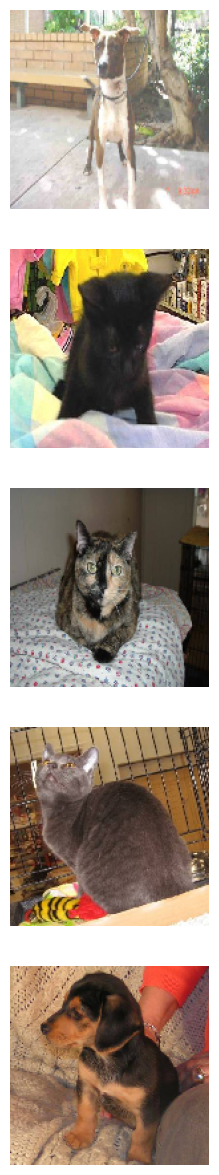

In [48]:
# 4
def plotImages(images_arr, probabilities = False):
    fig, axes = plt.subplots(len(images_arr), 1, figsize=(5,len(images_arr) * 3))
    if probabilities is False:
      for img, ax in zip( images_arr, axes):
          ax.imshow(img)
          ax.axis('off')
    else:
      for img, probability, ax in zip( images_arr, probabilities, axes):
          ax.imshow(img)
          ax.axis('off')
          if probability > 0.5:
              ax.set_title("%.2f" % (probability*100) + "% dog")
          else:
              ax.set_title("%.2f" % ((1-probability)*100) + "% cat")
    plt.show()

sample_training_images, _ = next(train_data_gen)
plotImages(sample_training_images[:5])


In [49]:
# 5
train_image_generator = ImageDataGenerator(rescale=1./255,
                                           rotation_range = 45,
                                           width_shift_range=0.3,
                                           height_shift_range=0.3,
                                           shear_range=12,
                                           zoom_range=0.3)


Found 2000 images belonging to 2 classes.


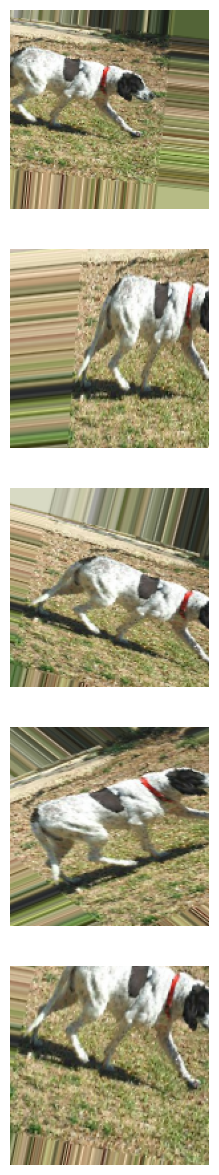

In [50]:
# 6
train_data_gen = train_image_generator.flow_from_directory(batch_size=batch_size,
                                                     directory=train_dir,
                                                     target_size=(IMG_HEIGHT, IMG_WIDTH),
                                                     class_mode="sparse")

augmented_images = [train_data_gen[0][0][0] for i in range(5)]

plotImages(augmented_images)

In [52]:
# 7
model = Sequential([
    Conv2D(filters=16,kernel_size=(3,3), padding="same",activation="relu",input_shape=(IMG_HEIGHT,IMG_WIDTH,3)),
    MaxPooling2D(),
    Conv2D(filters=32, kernel_size=(3,3),padding="same",activation="relu"),
    MaxPooling2D(),
    Conv2D(filters=64, kernel_size=(3,3), padding="same",activation="relu"),
    MaxPooling2D(),
    Flatten(),
    Dense(150,activation="relu"),
    Dense(2)
])


model.compile(optimizer="adam",
              loss=tf.keras.losses.SparseCategoricalCrossentropy(from_logits=True),
              metrics=["accuracy"])






model.summary()

Model: "sequential_7"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_24 (Conv2D)              │ (None, 150, 150, 16)   │           448 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_24 (MaxPooling2D) │ (None, 75, 75, 16)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_25 (Conv2D)              │ (None, 75, 75, 32)     │         4,640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_25 (MaxPooling2D) │ (None, 37, 37, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_26 (Conv2D)              │ (None, 37, 37, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_26 (MaxPooling2D) │ (None, 18, 18, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_8 (Flatten)             │ (None, 20736)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_15 (Dense)                │ (None, 150)            │     3,110,550 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_16 (Dense)                │ (None, 2)              │           302 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,134,436 (11.96 MB)

 Trainable params: 3,134,436 (11.96 MB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
# 8
history = model.fit(x=train_data_gen,
                    epochs=epochs,
                    validation_data=val_data_gen)

Epoch 1/15
15/15 ━━━━━━━━━━━━━━━━━━━━ 8s 487ms/step - accuracy: 0.4968 - loss: 0.8549 - val_accuracy: 0.5067 - val_loss: 0.6920
Epoch 2/15
 1/15 ━━━━━━━━━━━━━━━━━━━━ 2s 163ms/step - accuracy: 0.3672 - loss: 0.7227

/home/asterios/Projects/Courses/freecodeCamp/fcc_cat_dog/.venv/lib/python3.11/site-packages/keras/src/trainers/epoch_iterator.py:116: UserWarning: Your input ran out of data; interrupting training. Make sure that your dataset or generator can generate at least `steps_per_epoch * epochs` batches. You may need to use the `.repeat()` function when building your dataset.
  self._interrupted_warning()


15/15 ━━━━━━━━━━━━━━━━━━━━ 1s 58ms/step - accuracy: 0.3672 - loss: 0.7227 - val_accuracy: 0.5045 - val_loss: 0.6903
Epoch 3/15
15/15 ━━━━━━━━━━━━━━━━━━━━ 7s 481ms/step - accuracy: 0.5043 - loss: 0.6918 - val_accuracy: 0.5067 - val_loss: 0.6926
Epoch 4/15
15/15 ━━━━━━━━━━━━━━━━━━━━ 1s 57ms/step - accuracy: 0.6172 - loss: 0.6900 - val_accuracy: 0.4989 - val_loss: 0.6928
Epoch 5/15
15/15 ━━━━━━━━━━━━━━━━━━━━ 7s 485ms/step - accuracy: 0.4952 - loss: 0.6926 - val_accuracy: 0.5145 - val_loss: 0.6914
Epoch 6/15
15/15 ━━━━━━━━━━━━━━━━━━━━ 1s 59ms/step - accuracy: 0.4219 - loss: 0.6968 - val_accuracy: 0.5179 - val_loss: 0.6911
Epoch 7/15
15/15 ━━━━━━━━━━━━━━━━━━━━ 10s 649ms/step - accuracy: 0.5656 - loss: 0.6902 - val_accuracy: 0.5603 - val_loss: 0.6879
Epoch 8/15
15/15 ━━━━━━━━━━━━━━━━━━━━ 1s 85ms/step - accuracy: 0.5625 - loss: 0.6809 - val_accuracy: 0.5837 - val_loss: 0.6866
Epoch 9/15
15/15 ━━━━━━━━━━━━━━━━━━━━ 10s 656ms/step - accuracy: 0.5540 - loss: 0.6911 - val_accuracy: 0.5781 - val_lo

In [ ]:
# 9
acc = history.history['accuracy']
val_acc = history.history['val_accuracy']

loss = history.history['loss']
val_loss = history.history['val_loss']

epochs_range = range(epochs)

plt.figure(figsize=(8, 8))
plt.subplot(1, 2, 1)
plt.plot(epochs_range, acc, label='Training Accuracy')
plt.plot(epochs_range, val_acc, label='Validation Accuracy')
plt.legend(loc='lower right')
plt.title('Training and Validation Accuracy')

plt.subplot(1, 2, 2)
plt.plot(epochs_range, loss, label='Training Loss')
plt.plot(epochs_range, val_loss, label='Validation Loss')
plt.legend(loc='upper right')
plt.title('Training and Validation Loss')
plt.show()

In [ ]:
# 11
answers =  [1, 0, 0, 1, 0, 0, 0, 0, 1, 1, 0,
            1, 0, 1, 0, 1, 1, 0, 1, 1, 0, 0,
            1, 1, 1, 1, 1, 0, 0, 0, 0, 0, 1,
            1, 0, 1, 1, 1, 1, 0, 1, 0, 1, 1,
            0, 0, 0, 0, 0, 0]

correct = 0

for probability, answer in zip(probabilities, answers):
  if round(probability) == answer:
    correct +=1

percentage_identified = (correct / len(answers)) * 100

passed_challenge = percentage_identified >= 63

print(f"Your model correctly identified {round(percentage_identified, 2)}% of the images of cats and dogs.")

if passed_challenge:
  print("You passed the challenge!")
else:
  print("You haven't passed yet. Your model should identify at least 63% of the images. Keep trying. You will get it!")